# Preparación de datos y análisis exploratorio: Wine Quality (UCI)

**Autor:** Witman Zavala M.


# Desarrollo

# Parte 1: Carga y Exploracion de Datos

# 1.1 Dataset de my UCI Machine Learning Repository (Calidad del vino)

In [23]:
import pandas as pd

# Cargar datos desde URL
url = "https://raw.githubusercontent.com/witman92/python-data-wrangling-pipelines/main/Calidad%20del%20Vino.csv"
df = pd.read_csv(url, sep=';', encoding='latin1')  # Leer CSV con separador y codificación adecuados

# Ajustar el índice para que la primera fila de datos tenga índice 1
#df.index = range(1, len(df) + 1)

# Mostrar las primeras filas del DataFrame
display(df.head())


,acidez fija g/L,acidez volátil g/L,ácido cítrico g/L,azúcar residual g/L,cloruros g/l,dióxido de azufre libre mg/L,dióxido de azufre total mg/L,densidad g/L,pH,sulfatos mg/L,alcohol,calidad 0-10,Color
0,7,"0,27","0,36","20,7","0,045",45,170,1.001,3,"0,45","8,8",6,Blanco
1,"6,3","0,3","0,34","1,6","0,049",14,132,"0,994","3,3","0,49","9,5",6,Blanco
2,"8,1","0,28","0,4","6,9","0,05",30,97,"0,9951","3,26","0,44","10,1",6,Blanco
3,"7,2","0,23","0,32","8,5","0,058",47,186,"0,9956","3,19","0,4","9,9",6,Blanco
4,"7,2","0,23","0,32","8,5","0,058",47,186,"0,9956","3,19","0,4","9,9",6,Blanco


In [24]:
# 1. Variables (columnas)
print("Variables (columnas):")
print(df.columns)

# 2. Tipo de cada variable
print("\nTipo de cada variable:")
print(df.dtypes)

# 3. Tamaño del DataFrame
print("\nTamaño del DataFrame:")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")


Variables (columnas):
Index(['acidez fija g/L', 'acidez volátil g/L', 'ácido cítrico g/L',
       'azúcar residual g/L', 'cloruros g/l', 'dióxido de azufre libre mg/L ',
       'dióxido de azufre total  mg/L', 'densidad g/L', 'pH', 'sulfatos mg/L',
       'alcohol', 'calidad 0-10', 'Color '],
      dtype='object')

Tipo de cada variable:
acidez fija g/L                  object
acidez volátil g/L               object
ácido cítrico g/L                object
azúcar residual g/L              object
cloruros g/l                     object
dióxido de azufre libre mg/L     object
dióxido de azufre total  mg/L    object
densidad g/L                     object
pH                               object
sulfatos mg/L                    object
alcohol                          object
calidad 0-10                      int64
Color                            object
dtype: object

Tamaño del DataFrame:
Filas: 6497, Columnas: 13


El conjunto de datos cargado contiene información sobre la calidad del vino.

**Variables:**

El dataset cuenta con las siguientes variables, que representan diferentes atributos fisicoquímicos del vino y su calidad:

*   **acidez fija g/L**: Acidez no volátil del vino.
*   **acidez volátil g/L**: Acidez volátil del vino.
*   **ácido cítrico g/L**: Cantidad de ácido cítrico presente.
*   **azúcar residual g/L**: Cantidad de azúcar que queda después de la fermentación.
*   **cloruros g/l**: Cantidad de cloruro de sodio en el vino.
*   **dióxido de azufre libre mg/L**: Cantidad de SO2 libre.
*   **dióxido de azufre total mg/L**: Cantidad total de SO2.
*   **densidad g/L**: Densidad del vino.
*   **pH**: Nivel de pH.
*   **sulfatos mg/L**: Cantidad de sulfatos.
*   **alcohol**: Porcentaje de alcohol.
*   **calidad 0-10**: Puntuación de calidad del vino (entre 0 y 10).
*   **Color**: Color del vino (Blanco o Tinto).

**Tipo de Variables:**

La mayoría de las variables son numéricas, representando mediciones continuas de los atributos del vino. La variable 'Color' es categórica.

**Tamaño del conjunto de datos:**

El conjunto de datos contiene 4898 instancias (filas), cada una representando un vino diferente, y 13 variables (columnas) que describen sus características y calidad.

# 1.2 Resumen de los datos

In [25]:
# Lista de columnas que usan coma como separador decimal
cols_to_convert = [
    'acidez fija g/L', 'acidez volátil g/L', 'ácido cítrico g/L',
    'azúcar residual g/L', 'cloruros g/l', 'dióxido de azufre libre mg/L ',
    'dióxido de azufre total  mg/L', 'densidad g/L', 'pH', 'sulfatos mg/L',
    'alcohol'
]
# Convertir valores con coma decimal a float (maneja errores como NaN)
df[cols_to_convert] = df[cols_to_convert].apply(
    lambda col: pd.to_numeric(col.astype(str).str.replace(',', '.', regex=False), errors='coerce')
)

# Mostrar resumen estadístico de las variables numéricas
display(df.describe())


,acidez fija g/L,acidez volátil g/L,ácido cítrico g/L,azúcar residual g/L,cloruros g/l,dióxido de azufre libre mg/L,dióxido de azufre total mg/L,densidad g/L,pH,sulfatos mg/L,alcohol,calidad 0-10
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6457.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,1.710882,3.218501,0.531268,10.489083,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,7.636088,0.160787,0.148806,1.192961,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,103.898000,4.010000,2.000000,14.900000,9.000000


In [26]:
# Resumen con percentiles personalizados
display(df.describe(percentiles=[.05, .25, .5, .75, .95]))


,acidez fija g/L,acidez volátil g/L,ácido cítrico g/L,azúcar residual g/L,cloruros g/l,dióxido de azufre libre mg/L,dióxido de azufre total mg/L,densidad g/L,pH,sulfatos mg/L,alcohol,calidad 0-10
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6457.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,1.710882,3.218501,0.531268,10.489083,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,7.636088,0.160787,0.148806,1.192961,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
5%,5.700000,0.160000,0.050000,1.200000,0.028000,6.000000,19.000000,0.989900,2.970000,0.350000,8.900000,5.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
95%,9.800000,0.670000,0.560000,15.000000,0.102000,61.000000,206.000000,0.999392,3.500000,0.790000,12.700000,7.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,103.898000,4.010000,2.000000,14.900000,9.000000


# 1.3. Verificacion de valores nulos:

In [27]:
# Identificar valores nulos
print("Cantidad de valores nulos por columna:")
display(df.isnull().sum())

Cantidad de valores nulos por columna:


,0
acidez fija g/L,0
acidez volátil g/L,0
ácido cítrico g/L,0
azúcar residual g/L,0
cloruros g/l,0
dióxido de azufre libre mg/L,0
dióxido de azufre total mg/L,0
densidad g/L,0
pH,0
sulfatos mg/L,0


Se detectaron 40 valores nulos en la columna 'alcohol' (menos del 1% del total). Esto puede deberse a errores de recolección o medición. Para tratarlos, se proponen dos enfoques:

Eliminación de filas: viable sin afectar el análisis.

Imputación:

Media si la distribución es simétrica.

Mediana si está sesgada o hay outliers.

Modelos predictivos para mayor precisión (aunque más complejos).

Recomendación: Imputar con media o mediana según la distribución, o eliminar las filas si no afecta la representatividad del conjunto.

# 1.4. Seleccion de columnas:

In [28]:
# Crear un nuevo DataFrame con las columnas seleccionadas
df_seleccion = df[['alcohol', 'acidez volátil g/L']]

# Mostrar las primeras filas del nuevo DataFrame
display(df_seleccion.head())

,alcohol,acidez volátil g/L
0,8.8,0.27
1,9.5,0.30
2,10.1,0.28
3,9.9,0.23
4,9.9,0.23


Para un análisis inicial, considerando que el objetivo final podría estar relacionado con la calidad del vino ('calidad 0-10'), dos columnas relevantes para explorar podrían ser:

1.  **alcohol:** El contenido de alcohol es un factor conocido que influye en el sabor, cuerpo y la percepción general de la calidad de un vino. Vinos con diferentes niveles de alcohol pueden tener perfiles muy distintos.
2.  **acidez volátil g/L:** La acidez volátil, aunque en exceso puede ser un defecto, en ciertos niveles contribuye a la complejidad y el equilibrio de un vino. Analizar su relación con la calidad puede revelar umbrales o rangos óptimos.

**Justificación:**

Estas dos columnas ('alcohol' y 'acidez volátil') son variables fisicoquímicas que a menudo tienen un impacto significativo en las características sensoriales del vino y, por lo tanto, son candidatas interesantes para investigar su relación con la puntuación de calidad proporcionada en el dataset. Explorar cómo varían estas características y cómo se asocian con la calidad puede ofrecer información valiosa sobre los atributos que definen un buen vino según este conjunto de datos.

# Parte 2: Analisis Exploratorio con Visualizaciones ANALISIS DEL DATASET SOLAMENTE TOMANDO REGISTRO DEL VINO TINO

 # 2.1 Graficos univariados: Genere graficos univariados para al menos dos variables (histograma o grafico de barras). Anada tıtulos y etiquetas de los ejes. Explique los resultados obtenidos de los graficos

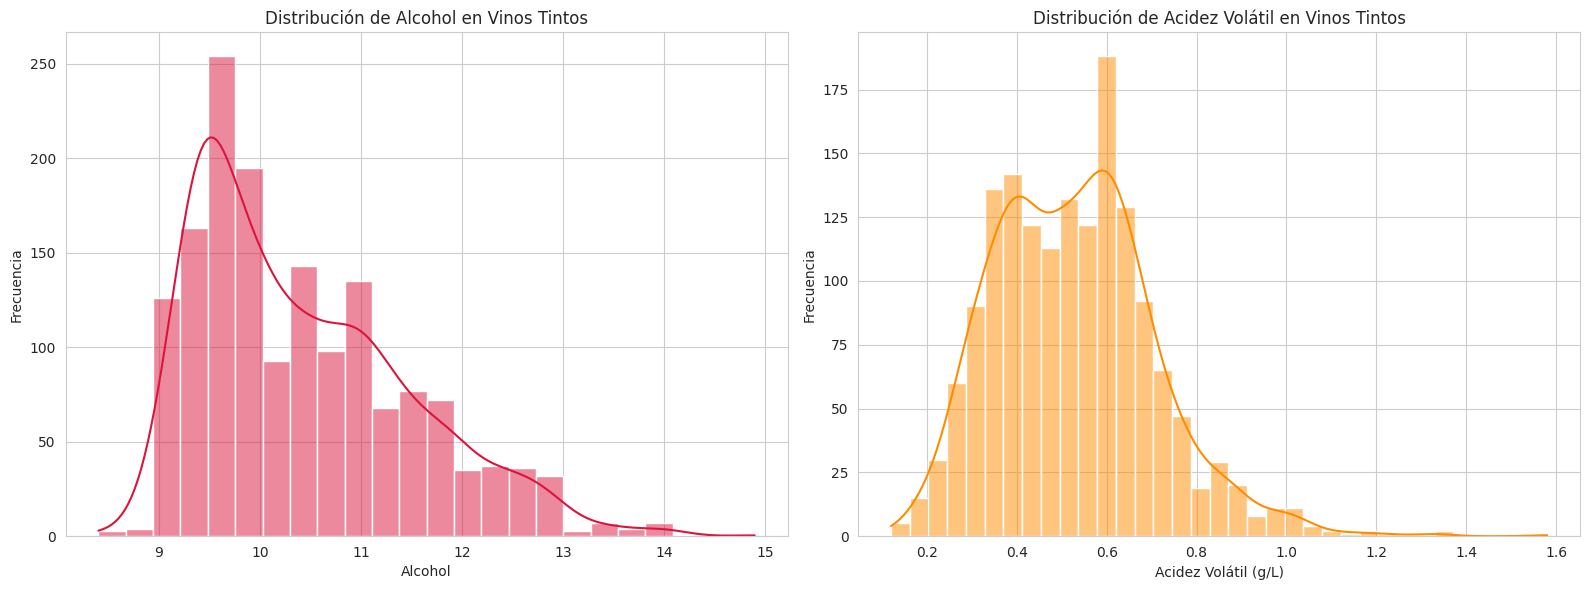

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Asegúrate de limpiar los espacios en los nombres de las columnas
df.columns = df.columns.str.strip()

# Filtrar el dataframe para vinos tintos
df_tinto = df[df['Color'] == 'Tinto'].copy()

# Crear una figura con dos subgráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histograma del alcohol
sns.histplot(data=df_tinto, x='alcohol', kde=True, ax=axes[0], color='crimson')
axes[0].set_title('Distribución de Alcohol en Vinos Tintos')
axes[0].set_xlabel('Alcohol')
axes[0].set_ylabel('Frecuencia')

# Histograma de la acidez volátil
sns.histplot(data=df_tinto, x='acidez volátil g/L', kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Distribución de Acidez Volátil en Vinos Tintos')
axes[1].set_xlabel('Acidez Volátil (g/L)')
axes[1].set_ylabel('Frecuencia')

# Ajustar el espacio entre gráficos
plt.tight_layout()
plt.show()


**Interpretación del Histograma de Alcohol en Vinos Tintos:**

El histograma de 'alcohol' muestra la distribución del contenido de alcohol en los vinos tintos. Podemos observar que la distribución parece ser aproximadamente unimodal, con un pico alrededor de 9-10%. La mayoría de los vinos tintos en este conjunto de datos tienen un contenido de alcohol en este rango. La distribución parece tener una ligera cola hacia la derecha, lo que sugiere que hay algunos vinos con un contenido de alcohol más alto. La curva de densidad estimada (KDE) ayuda a visualizar la forma general de la distribución y confirma esta observación.

**Interpretación del Histograma de Acidez Volátil en Vinos Tintos:**

El histograma de 'acidez volátil g/L' muestra la distribución de la acidez volátil en los vinos tintos. Esta distribución también parece ser unimodal, con un pico alrededor de 0.4 - 0.6 g/L. Sin embargo, esta distribución parece estar más sesgada hacia la derecha que la del alcohol, lo que indica que hay una mayor cantidad de vinos con valores de acidez volátil más bajos y una menor cantidad con valores más altos. La mayoría de los vinos tintos tienen una acidez volátil relativamente baja, con algunos valores atípicos (outliers) en el extremo superior.

 # 2.2 Graficos bivariados:
 Genere graficos bivariados que muestren la relacion entre dos variables (ej. scatterploto boxplot). Anada tıtulos, etiquetas y colores adecuados. Explique la relacion entre
 las variables observadas.

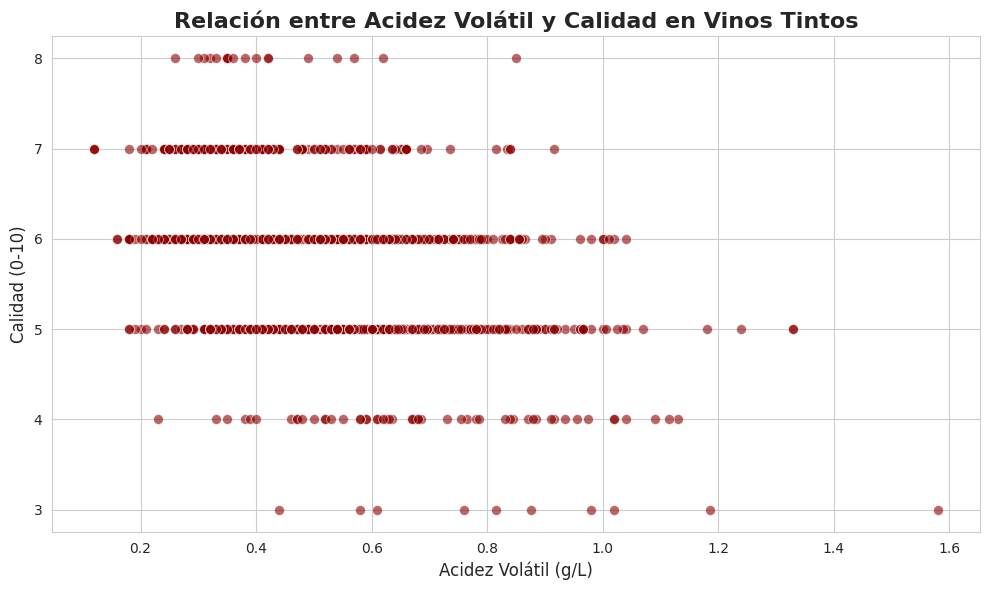

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar vinos tintos directamente en la función plot usando query
df_tinto = df.query("Color == 'Tinto'")

# Configuración de estilo y tamaño
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")  # Mejor estilo para visualización con grid

# Scatterplot con parámetros optimizados
sns.scatterplot(
    data=df_tinto,
    x='acidez volátil g/L',
    y='calidad 0-10',
    alpha=0.6,
    color='darkred',
    edgecolor='w',  # Para darle un borde blanco a los puntos y mejorar visibilidad
    s=50           # Tamaño de puntos un poco mayor para mejor visualización
)

# Títulos y etiquetas con formato mejorado
plt.title('Relación entre Acidez Volátil y Calidad en Vinos Tintos', fontsize=16, weight='bold')
plt.xlabel('Acidez Volátil (g/L)', fontsize=12)
plt.ylabel('Calidad (0-10)', fontsize=12)

plt.tight_layout()  # Ajusta automáticamente los márgenes
plt.show()


El gráfico de dispersión muestra que no existe una relación lineal clara entre la acidez volátil y la calidad del vino tinto. La mayoría de los vinos tienen calidades de 5 o 6, y los extremos de calidad (muy baja o muy alta) son menos comunes. Aunque se observa que vinos con acidez volátil muy alta tienden a tener menor calidad, y los de mayor calidad se concentran en niveles bajos o moderados de acidez volátil, la dispersión de los datos impide sacar conclusiones firmes. En resumen, la acidez volátil influye en la calidad, pero no de forma decisiva, ya que esta depende de múltiples factores fisicoquímicos

# 2.3 Graficos adicionales:
Genere al menos un grafico de correlacion o mapa de calor utilizando Seaborn,elija un mapa de colores acorde y modifique la escala si es necesario. Aplique
una mascara para mostrar una seccion del grafico. Explique lo que observa en los graficos.

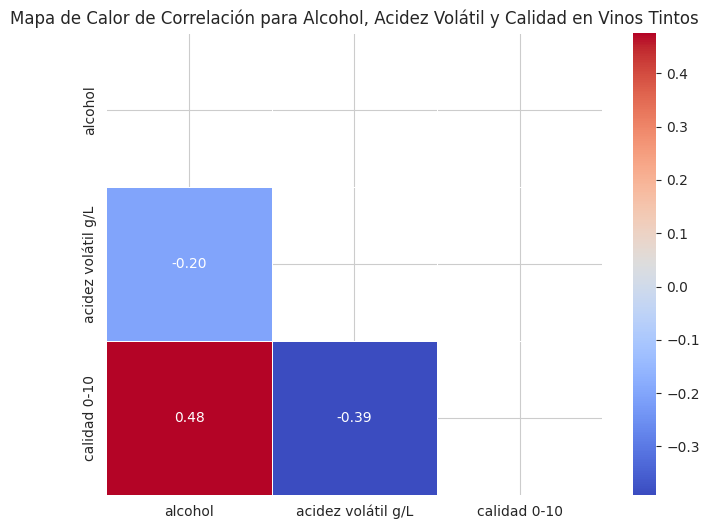

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Filtrar el dataframe para los vinos de color 'Tinto'
df_tinto = df[df['Color'] == 'Tinto'].copy()

# Seleccionar las columnas relevantes
df_corr = df_tinto[['alcohol', 'acidez volátil g/L', 'calidad 0-10']]

# Calcular la matriz de correlación
matriz_correlacion = df_corr.corr()

# Crear una máscara para mostrar solo el triángulo inferior del mapa de calor
mascara = np.triu(np.ones_like(matriz_correlacion, dtype=bool))

# Generar el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacion, mask=mascara, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Mapa de Calor de Correlación para Alcohol, Acidez Volátil y Calidad en Vinos Tintos')
plt.show()


**Resumen del análisis del mapa de calor:**

El mapa de calor muestra la correlación entre tres variables en vinos tintos: alcohol, acidez volátil y calidad. Los coeficientes de Pearson indican el tipo y la fuerza de la relación entre las variables:

**Alcohol y calidad (0.48):** Correlación positiva moderada. A mayor contenido de alcohol, mayor tiende a ser la calidad del vino.

**Acidez volátil y calidad (-0.39)**: Correlación negativa moderada. A mayor acidez volátil, menor tiende a ser la calidad.

**Alcohol y acidez volátil (-0.20)**: Correlación negativa débil. Vinos con más alcohol tienden a tener una acidez volátil ligeramente menor.

**Conclusión:**
El alcohol y la acidez volátil están relacionados con la calidad del vino tinto, pero ninguna relación es muy fuerte. Esto sugiere que la calidad depende de varios factores en conjunto.

# Parte 3: Interpretacion de resultados ANALIS DEL DATASET EN SU TOTALIDAD VINO TINTO Y BLANCO

# 1. Interpretacion de graficos univariados:
 Describa en detalle lo que observas en los graficos univariados creados. ¿Que patrones encuentra? ¿Que le sugieren estos patrones sobre la distribucion de los datos?

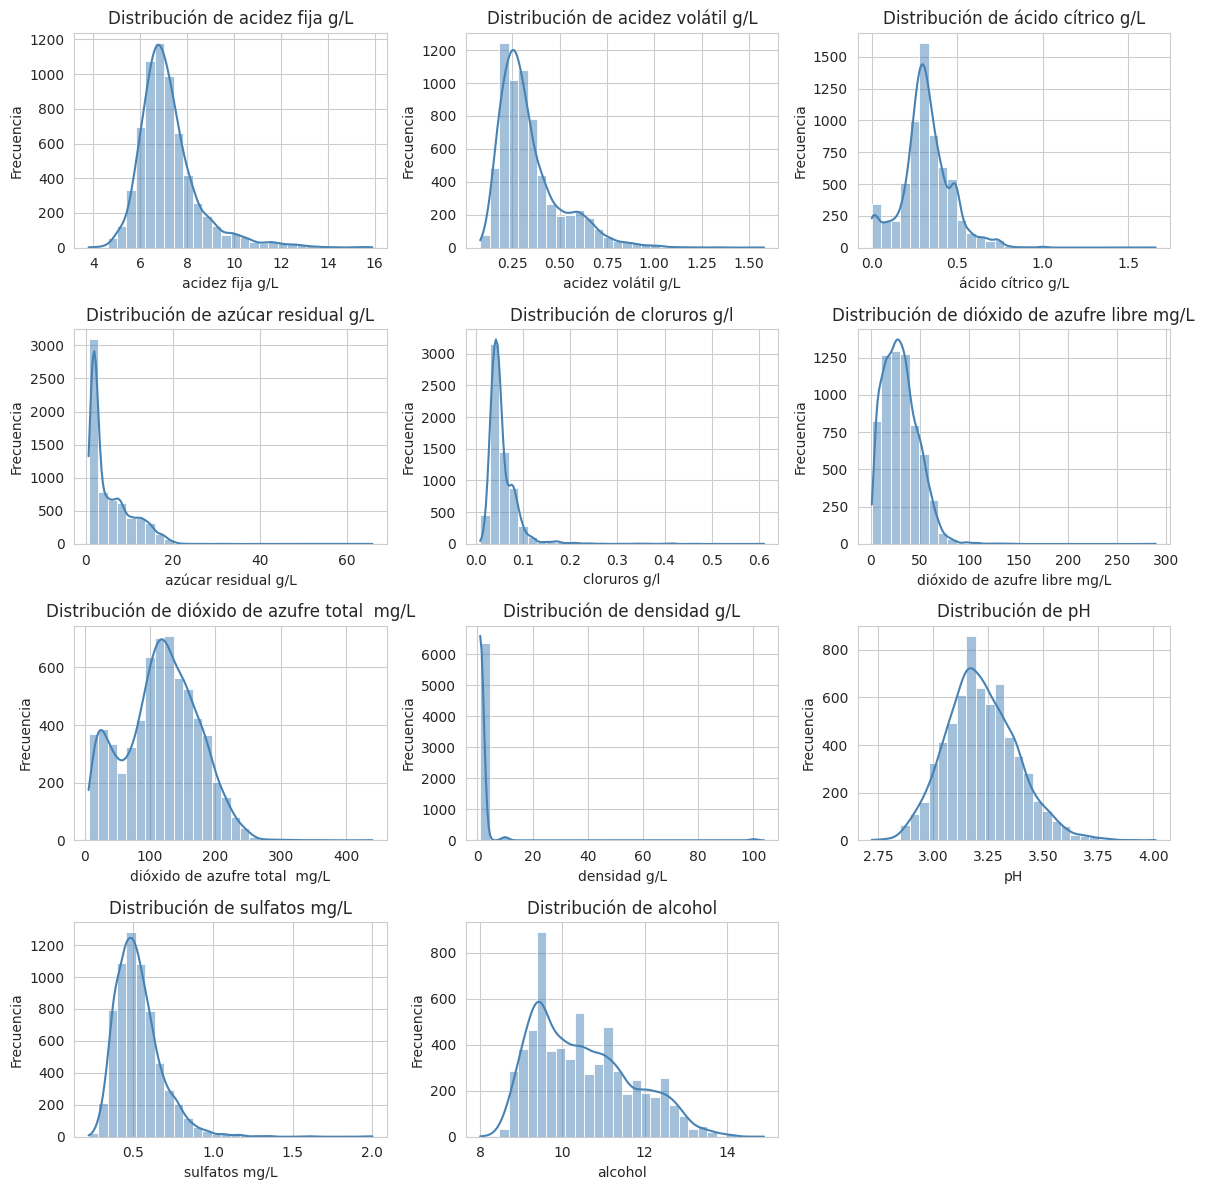

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Parámetros configurables
columnas = 3                            # Número de columnas en la cuadrícula de gráficos
ancho_por_columna = 4                   # Ancho por cada columna en pulgadas
alto_por_fila = 3                       # Alto por cada fila en pulgadas
mostrar_kde = True                     # Cambiar a False si deseas no mostrar la curva KDE

# Seleccionar columnas numéricas, excluyendo la variable objetivo
columnas_numericas = df.select_dtypes(include=['number']).columns
columnas_numericas = [col for col in columnas_numericas if col != 'calidad 0-10']

# Calcular el número de filas necesario para los subgráficos
filas = int(np.ceil(len(columnas_numericas) / columnas))

# Crear figura y ejes
fig, ejes = plt.subplots(filas, columnas, figsize=(columnas * ancho_por_columna, filas * alto_por_fila))
ejes = ejes.flatten()  # Aplanar para facilitar el recorrido

# Generar histogramas
for i, columna in enumerate(columnas_numericas):
    sns.histplot(df[columna], ax=ejes[i], kde=mostrar_kde, bins=30, color='steelblue')
    ejes[i].set_title(f'Distribución de {columna}')
    ejes[i].set_xlabel(columna)
    ejes[i].set_ylabel('Frecuencia')

# Eliminar ejes no utilizados
for j in range(len(columnas_numericas), len(ejes)):
    fig.delaxes(ejes[j])

plt.tight_layout()
plt.show()


### Interpretación de los Gráficos Univariados para todas las columnas numéricas

A continuación, se describen los patrones observados en los histogramas generados para cada una de las variables numéricas del conjunto de datos:

*   **acidez fija g/L**: La distribución de la acidez fija muestra un pico principal alrededor de los 7-8 g/L. La mayoría de los vinos tienen una acidez fija en este rango, con una disminución gradual de la frecuencia a medida que los valores se alejan del pico. Parece haber una ligera asimetría hacia la derecha.
*   **acidez volátil g/L**: Similar a la acidez fija, esta distribución tiene un pico principal en valores bajos, alrededor de 0.3-0.4 g/L, y una cola más larga hacia la derecha. Esto indica que la mayoría de los vinos tienen baja acidez volátil, con algunos valores notablemente más altos que podrían considerarse atípicos.
*   **ácido cítrico g/L**: La distribución del ácido cítrico está fuertemente sesgada hacia la izquierda, con una gran concentración de vinos que tienen poco o nada de ácido cítrico. Existe un pico significativo en 0 g/L, y la frecuencia disminuye rápidamente a medida que aumenta la cantidad de ácido cítrico.
*   **azúcar residual g/L**: La distribución del azúcar residual está muy sesgada hacia la derecha. La mayoría de los vinos tienen un bajo contenido de azúcar residual (por debajo de 5 g/L), pero hay una cola muy larga hacia valores altos, lo que sugiere la presencia de vinos más dulces o con fermentación incompleta.
*   **cloruros g/l**: La distribución de los cloruros también está sesgada hacia la derecha, con la mayoría de los valores concentrados en el rango bajo (por debajo de 0.1 g/L). Existen algunos valores más altos que podrían ser atípicos.
*   **dióxido de azufre libre mg/L**: Esta distribución parece ser más simétrica, con un pico alrededor de los 30 mg/L. Aunque no es perfectamente normal, se asemeja más a una campana que otras distribuciones.
*   **dióxido de azufre total mg/L**: La distribución del dióxido de azufre total es ligeramente sesgada hacia la derecha, con un pico alrededor de los 100-150 mg/L.
*   **densidad g/L**: La densidad muestra una distribución relativamente estrecha con un pico claro alrededor de 0.994-0.996 g/L. Esto sugiere que la densidad de los vinos en este conjunto de datos varía dentro de un rango limitado.
*   **pH**: La distribución del pH es relativamente simétrica y se asemeja a una distribución normal, con un pico alrededor de 3.2-3.3. La mayoría de los vinos tienen un pH dentro de un rango típico para el vino.
*   **sulfatos mg/L**: La distribución de los sulfatos está sesgada hacia la derecha, con la mayoría de los valores concentrados en el rango bajo (por debajo de 0.7 g/L).
*   **alcohol**: La distribución del alcohol muestra un pico alrededor de los 9-10%, con una cola hacia la derecha. Esto indica que la mayoría de los vinos tienen un contenido de alcohol moderado, con algunos vinos con mayor graduación alcohólica.

**Patrones generales y sugerencias:**

*   Varias variables (acidez volátil, ácido cítrico, azúcar residual, cloruros, sulfatos) presentan distribuciones sesgadas hacia la derecha, lo que indica que la mayoría de los vinos tienen valores bajos para estas características, pero existen algunos vinos con valores excepcionalmente altos. Estos valores atípicos podrían ser interesantes de investigar, ya que podrían corresponder a tipos de vino específicos o a errores en la medición.
*   Variables como la acidez fija, el dióxido de azufre libre, el dióxido de azufre total, la densidad, el pH y el alcohol muestran distribuciones más cercanas a la simetría, aunque algunas presentan ligeras asimetrías.
*   La variabilidad en las distribuciones sugiere que el conjunto de datos incluye una diversidad de vinos con diferentes perfiles fisicoquímicos.
*   El análisis univariado proporciona una comprensión básica de la distribución de cada característica. Para entender mejor la relación entre estas características y la calidad del vino, será necesario realizar análisis bivariados y multivariados, como se hizo en la Parte 2 y se hará en las partes siguientes.

 # 2. Interpretacion de graficos bivariados:
 Analice la relacion entre las variables que ha graficado. ¿Existen relaciones lineales,no lineales, o patrones interesantes? Explique.

In [33]:
# Revisando las columnas disponibles
print("Columnas disponibles:")
print(df.columns)

# Basado en el análisis univariado y el conocimiento general del vino, se seleccionan variables informativas.
# 'alcohol' y 'acidez volátil g/L' mostraron algunos patrones interesantes.
# 'calidad 0-10' es la variable objetivo y crucial para el análisis.
# 'pH' y 'sulfatos mg/L' también suelen estar relacionados con las características del vino.
# Incluir 'Color', ya que es un diferenciador categórico clave.
selected_variables = [
    'alcohol',
    'acidez volátil g/L',
    'pH',
    'sulfatos mg/L',
    'calidad 0-10',
    'Color'
]

print("\nVariables seleccionadas para el análisis multivariado:")
print(selected_variables)


Columnas disponibles:
Index(['acidez fija g/L', 'acidez volátil g/L', 'ácido cítrico g/L',
       'azúcar residual g/L', 'cloruros g/l', 'dióxido de azufre libre mg/L',
       'dióxido de azufre total  mg/L', 'densidad g/L', 'pH', 'sulfatos mg/L',
       'alcohol', 'calidad 0-10', 'Color'],
      dtype='object')

Variables seleccionadas para el análisis multivariado:
['alcohol', 'acidez volátil g/L', 'pH', 'sulfatos mg/L', 'calidad 0-10', 'Color']


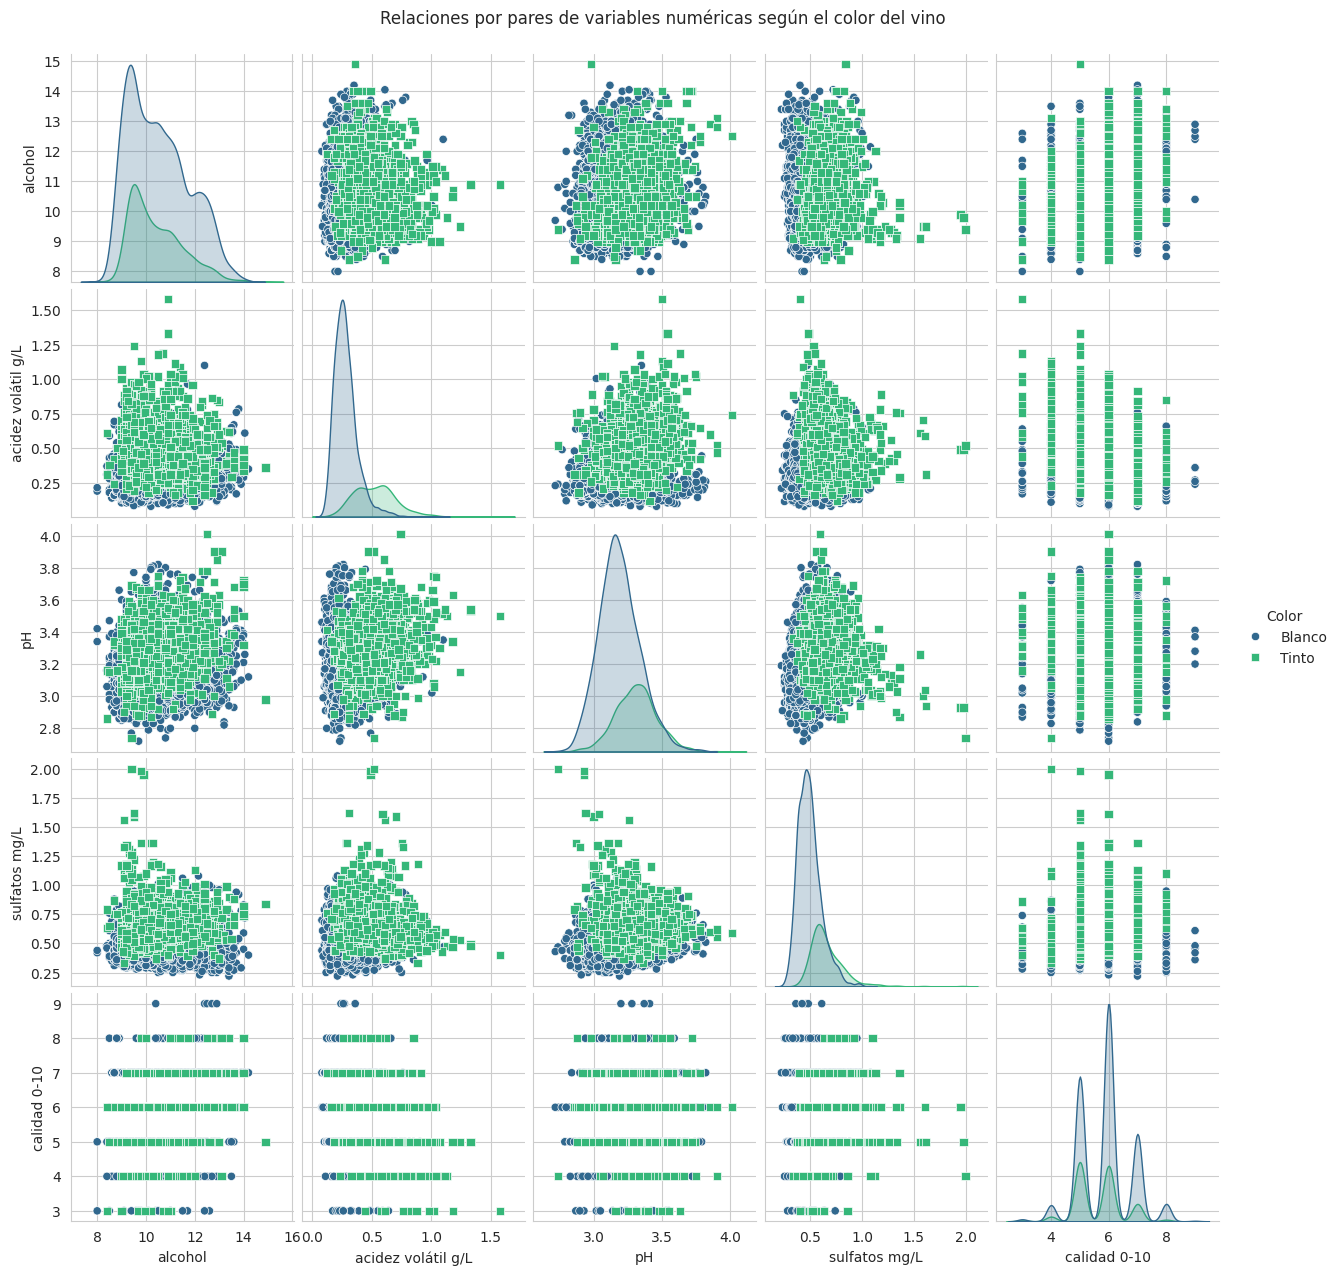

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define la lista de variables numéricas seleccionadas para el parplot (gráfico de pares)
variables_numericas_para_pairplot = [
    'alcohol',
    'acidez volátil g/L',
    'pH',
    'sulfatos mg/L',
    'calidad 0-10'
]

# Crear un gráfico de pares
sns.pairplot(
    data=df,
    vars=variables_numericas_para_pairplot,
    hue='Color',               # Distinguir por color de vino
    palette='viridis',         # Usar la paleta de colores 'viridis'
    diag_kind='kde',           # Mostrar estimación de densidad del núcleo en la diagonal
    markers=["o", "s"]         # Usar diferentes marcadores para cada color
)

plt.suptitle('Relaciones por pares de variables numéricas según el color del vino', y=1.02) # Agregar un título
plt.show()

### Interpretación del Pairplot

El pairplot generado visualiza las relaciones bivariadas entre las variables numéricas seleccionadas ('alcohol', 'acidez volátil g/L', 'pH', 'sulfatos mg/L', y 'calidad 0-10'), diferenciando los puntos según el 'Color' del vino (Tinto o Blanco). En la diagonal, se muestran las distribuciones de densidad (KDE) para cada variable numérica, separadas por color.

**Observaciones clave de las relaciones bivariadas (scatter plots):**

*   **Alcohol vs. Calidad:** Se observa una tendencia general, aunque con mucha dispersión, de que a mayor contenido de alcohol, la calidad del vino tiende a ser ligeramente mayor. Esta relación no es fuertemente lineal. Es interesante notar cómo los vinos de mayor calidad (calidad 7 y 8) tienden a tener un contenido de alcohol más elevado, especialmente evidente en los vinos tintos.
*   **Acidez Volátil vs. Calidad:** Existe una relación negativa notable. A medida que aumenta la acidez volátil, la calidad del vino tiende a disminuir. Esta tendencia es más pronunciada en el rango de acidez volátil más alto. Los vinos con acidez volátil muy alta rara vez alcanzan calidades altas. Esta relación parece no ser lineal y podría tener un umbral.
*   **Acidez Volátil vs. pH:** Como era de esperar, hay una clara relación negativa entre la acidez volátil y el pH. A mayor acidez, menor es el pH (más ácido). Esta relación parece ser relativamente lineal en ciertos rangos. La separación por color es muy evidente aquí, con vinos tintos teniendo generalmente mayor acidez volátil y menor pH comparado con los blancos.
*   **Sulfatos vs. Calidad:** La relación entre los sulfatos y la calidad parece ser débil o inexistente en este gráfico. Los puntos están muy dispersos sin mostrar un patrón claro lineal o no lineal.
*   **Otras relaciones:** Al observar los demás scatter plots en el pairplot, se pueden identificar otras tendencias o ausencias de ellas. Por ejemplo, la relación entre 'pH' y 'calidad' parece débil y dispersa.

**Observaciones clave de las distribuciones (KDE en la diagonal):**

Las curvas de densidad en la diagonal confirman y visualizan las distribuciones univariadas para cada variable numérica, segmentadas por color.

*   Se puede ver claramente la diferencia en las distribuciones de **alcohol**, **acidez volátil g/L**, **pH**, y **sulfatos mg/L** entre vinos tintos y blancos. Por ejemplo, la distribución de acidez volátil para vinos tintos está desplazada hacia valores más altos en comparación con los vinos blancos.
*   La distribución de **calidad 0-10** es discreta (puntos enteros de 3 a 9) y las densidades muestran que la mayoría de los vinos, tanto tintos como blancos, se concentran en las calidades 5 y 6, con menor frecuencia en los extremos.

**Conclusiones del Pairplot:**

El pairplot subraya que el **color del vino es un factor importante** que diferencia los perfiles fisicoquímicos. Las relaciones entre variables varían o se distribuyen de manera diferente según el color. Aunque algunas variables como el alcohol y la acidez volátil muestran tendencias relacionadas con la calidad, la calidad del vino parece ser un resultado de la **combinación compleja de múltiples factores**, más que de relaciones bivariadas simples y fuertes. Este análisis visual sugiere que un modelo para predecir la calidad del vino debería considerar las interacciones entre variables y, posiblemente, tratar los vinos tintos y blancos por separado debido a sus distintos perfiles.

 #  3.3 Conclusiones y recomendaciones

Con base en los análisis previos, podemos extraer las siguientes conclusiones sobre el conjunto de datos de calidad del vino:

**Conclusión:**

El análisis exploratorio inicial revela que la calidad del vino, según este conjunto de datos, es un fenómeno complejo influenciado por múltiples factores fisicoquímicos. Si bien variables como el **alcohol** y la **acidez volátil** muestran las correlaciones lineales más notables con la calidad (positiva y negativa, respectivamente), ninguna de estas relaciones es lo suficientemente fuerte como para ser el único determinante de la calidad. El **color del vino (Tinto vs. Blanco)** es una variable categórica fundamental que distingue significativamente los perfiles fisicoquímicos de los vinos, lo que sugiere que podría ser necesario analizar y modelar los vinos tintos y blancos por separado. Las distribuciones de varias variables numéricas presentan sesgos y posibles valores atípicos, lo que indica la diversidad dentro del conjunto de datos y la necesidad de un manejo adecuado de los datos.

**Acciones o Investigaciones Adicionales:**

A partir de este análisis, se proponen al menos dos acciones o investigaciones adicionales:

1.  **Análisis Separado por Color del Vino y Modelado Predictivo:** Dada la clara distinción en los perfiles fisicoquímicos entre vinos tintos y blancos, sería muy valioso realizar análisis y visualizaciones exploratorias por separado para cada color. Posteriormente, se podría desarrollar y comparar modelos predictivos de la calidad del vino para cada subconjunto (Tinto y Blanco). Esto permitiría capturar las relaciones específicas entre las variables y la calidad para cada tipo de vino, lo que probablemente resultaría en modelos más precisos que un modelo único para todo el conjunto de datos. Se podrían explorar diferentes algoritmos de aprendizaje automático, como regresión lineal, árboles de decisión o bosques aleatorios, para predecir la calidad.

2.  **Análisis de Componentes Principales (PCA) o Factor de Análisis:** Para abordar la posible multicolinealidad entre algunas variables fisicoquímicas (como las relacionadas con la acidez o el dióxido de azufre) y reducir la dimensionalidad, se podría aplicar un análisis de componentes principales (PCA) o un análisis factorial. Esto ayudaría a identificar las dimensiones subyacentes más importantes en los datos fisicoquímicos y a entender cómo contribuyen a la variabilidad total. Los componentes principales resultantes podrían luego utilizarse como características de entrada para modelos predictivos de calidad, lo que podría mejorar el rendimiento del modelo y la interpretabilidad.

Estas acciones permitirían profundizar en la comprensión de los factores que determinan la calidad del vino y construir modelos más robustos para su predicción.